# Code for ECO1465 project paper 
## Can New Information on Climate Policy Persuade Climate Skeptics?
### Main notebook to run each section

In [33]:
%load_ext autoreload
%autoreload 2
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
pd.set_option("display.width", 200)
pd.set_option("display.max_rows", 80)

from Scripts.data import data_path
from Scripts.runner import Runner
print("data:", data_path())

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
data: C:\Users\abrar\OneDrive - University of Toronto\Classes\ECO1465\Project_Code\data\all.dta


In [ ]:
# ---------------------------------------------------------------------------------
# Sections to run: set any to False to skip it. The sections are listed in paper order.
# ---------------------------------------------------------------------------------
RUN = {
    # A. Data and design (Reports 1 and 2)
    "summary_stats":      True,   # descriptives, Table A15 estimates, balance, data quality       ~30 s
    "descriptives":       True,   # Summary-statistics by treatment group
    "balance":            True,   # Balance table and plot
    "compliance":         True,   # Compliance table for self-reported video treatment
    "table_a15":            True,   # replication of Table A15 in the original paper
    # B. Linear models and variable selection (Report 3)
    "ols":                True,
    "ridge":              True,
    "lasso":              True,
    "compare_linear":     True,   # Compare OLS, ridge, and lasso
    "double_lasso":       False,   
    "a15_penalized":      False,   # Alternative specification based onTable A15
    # C. Trees and ensembles (Report 4)
    "regression_tree":    False,   # Regression tree
    "bagging_rf":         False,   # Bagging with random forests
    "boosting":           False,   # Boosting with gradient boosting
    "error_comparison":   False,   # Generate table comparing errors of different models
    # D. Causal graphs (Report 5)
    "dags":               True,   # DAGs and causal graphs
}
run = Runner(RUN)      # re-run this cell after changing RUN

---
# A. Data and design (Reports 1 and 2)

## 1. Summary statistics, balance and data quality
`Scripts/s01_summary_stats.py`.

Outputs: `summary_table_key_variables.tex`, `table_descriptives.tex`, `table_a15_country_fe.tex`

In [35]:
run("summary_stats");

[running] summary_stats: Summary statistics, Table A15 estimates, balance and data quality
40,680 rows
college raw coding (1/2, not 0/1): {1: 20388, 2: 20292}

1. Descriptive statistics (unweighted and weighted)


,N,miss_pct,mean,median,sd,min,p25,p75,max,unique,w_mean,w_sd
variable,,,,,,,,,,,,
standard_support,40680,0.000,0.444,1.000,1.247,-2.000,0.000,1.000,2.000,5,0.430,1.249
investments_support,40680,0.000,0.827,1.000,1.064,-2.000,0.000,2.000,2.000,5,0.814,1.067
tax_transfers_support,40680,0.000,0.435,1.000,1.192,-2.000,0.000,1.000,2.000,5,0.417,1.191
index_fairness,40680,0.000,0.014,0.173,1.002,-2.505,-0.485,0.840,1.535,125,0.000,1.000
index_willing_change,40680,0.000,0.013,0.031,0.999,-2.581,-0.622,0.684,1.771,3080,0.000,1.000
index_main_policies,40680,0.000,0.015,0.124,1.003,-2.566,-0.565,0.761,1.435,125,0.000,1.000
standard_support_bin,40680,0.000,0.553,1.000,0.497,0.000,0.000,1.000,1.000,2,0.547,0.498
investments_support_bin,40680,0.000,0.684,1.000,0.465,0.000,0.000,1.000,1.000,2,0.678,0.467
tax_transfers_support_bin,40680,0.000,0.527,1.000,0.499,0.000,0.000,1.000,1.000,2,0.519,0.500



2. Key variables


,Category,Variable,Type / scale,N,Miss %,Mean,Median,SD,Min,Max,Wtd mean
0,Treatment identifiers,Control group,"Binary {0,1}",40680,0.00,0.290,0.000,0.454,0.000,1.000,0.288
1,Treatment identifiers,Climate impacts treatment,"Binary {0,1}",40680,0.00,0.238,0.000,0.426,0.000,1.000,0.238
2,Treatment identifiers,Climate policies treatment,"Binary {0,1}",40680,0.00,0.238,0.000,0.426,0.000,1.000,0.239
3,Treatment identifiers,Both treatments combined,"Binary {0,1}",40680,0.00,0.235,0.000,0.424,0.000,1.000,0.234
4,Primary stated outcomes,Green infrastructure support,"Binary {0,1}",40680,0.00,0.684,1.000,0.465,0.000,1.000,0.678
5,Primary stated outcomes,Ban on combustion-engine cars,"Binary {0,1}",40680,0.00,0.553,1.000,0.497,0.000,1.000,0.547
6,Primary stated outcomes,Carbon tax w/ cash transfers,"Binary {0,1}",40680,0.00,0.527,1.000,0.499,0.000,1.000,0.519
7,Primary stated outcomes,Support main policies index,Std. z-score,40680,0.00,0.015,0.124,1.003,-2.566,1.435,0.000
8,Primary stated outcomes,Fairness of main policies index,Std. z-score,40680,0.00,0.014,0.173,1.002,-2.505,1.535,0.000
9,Real-stakes behaviours,Willing to donate lottery prize,"Binary {0,1}",40680,0.00,0.841,1.000,0.366,0.000,1.000,0.842


wrote output\tables\summary_table_key_variables.tex

3. Arm shares vs. design


...

,impacts,policies,sum,both_actual,gap
outcome,,,,,
standard_support_bin,0.0214,0.0432,0.0646,0.0726,0.0080
investments_support_bin,0.0203,0.0261,0.0464,0.0472,0.0008
tax_transfers_support_bin,0.0301,0.1017,0.1318,0.1293,-0.0025
index_fairness,0.0467,0.1335,0.1802,0.1900,0.0098
index_willing_change,0.0524,0.0156,0.0680,0.0766,0.0086



5. Balance: covariate means by arm, joint F-test


,control,Climate impacts,diff_2,p_2,Climate policies,diff_3,p_3,Both,diff_4,p_4
variable,,,,,,,,,,
female,0.5040,0.4993,-0.0048,0.4884,0.5037,-0.0003,0.9646,0.5137,0.0097,0.1581
college01,0.5053,0.5054,0.0001,0.9909,0.5021,-0.0032,0.6375,0.4910,-0.0143,0.0371
income_factor,2.4439,2.4579,0.0140,0.3519,2.4405,-0.0034,0.8227,2.4702,0.0263,0.0828
urban,0.7302,0.7331,0.0030,0.6257,0.7356,0.0055,0.3655,0.7297,-0.0005,0.9405
car_dependency,0.7756,0.7751,-0.0005,0.9237,0.7715,-0.0042,0.4679,0.7654,-0.0102,0.0779
home_owner,0.6702,0.6713,0.0011,0.8627,0.6670,-0.0031,0.6283,0.6693,-0.0009,0.8942
econ_leaning,3.1833,3.1867,0.0034,0.8469,3.1850,0.0017,0.9250,3.1677,-0.0156,0.3831


,arm,N,R2,F,p
0,Climate impacts,21433,0.00104,0.224,0.9798
1,Climate policies,21427,0.00066,0.204,0.9848
2,Both,21344,0.00207,2.098,0.0403



6. Data quality. Rows 40,680 | Countries 20 | exact duplicate rows 0
Missingness (%), variables with any:
rush_treatment    28.97
petition           9.18
urban              0.07
Constant columns (post-screening sample): ['valid', 'finished_attentive', 'attention_test']
Share missing rush_treatment: 0.2897 | control share: 0.2897 (structural)
Differential item non-response across arms (max - min, pp) above 0.5:
rush_treatment    100.0
--- watched_climate, arms (2, 4) (N=19,233) ---
watched_climate
Yes                                  0.8612
NaN                                  0.0891
No, there was a technical problem    0.0286
No, I skipped part of the video      0.0211
--- watched_policy, arms (3, 4) (N=19,233) ---
watched_policy
Yes                                  0.8535
NaN                                  0.0894
No, there was a technical problem    0.0318
No, I skipped part of the video      0.0253
Duration (minutes):
count    40680.00
mean        45.21
std        148.50
min      

## 2. Summary-statistics table and support by arm
`Scripts/s02_descriptives.py` · Outputs: `table_sumstats.tex`, `fig_support_by_arm.pdf`

[running] descriptives: Summary statistics table and support by arm
wrote output\tables\table_sumstats.tex
\begin{tabular}{lrrrrr}
\toprule
 & Mean & SD & Min & Max & Control mean \\
\midrule
\multicolumn{6}{l}{\textit{Outcomes}}\\
Supports carbon tax with cash transfers & 0.527 & 0.499 & 0.00 & 1.00 & 0.469 \\
Supports ban on combustion-engine cars & 0.553 & 0.497 & 0.00 & 1.00 & 0.523 \\
Supports green infrastructure program & 0.684 & 0.465 & 0.00 & 1.00 & 0.662 \\
Fairness of main policies index (z) & 0.014 & 1.002 & -2.50 & 1.54 & -0.072 \\
Willingness to change behavior index (z) & 0.013 & 0.999 & -2.58 & 1.77 & -0.019 \\
\addlinespace
\multicolumn{6}{l}{\textit{Treatment arms}}\\
Control & 0.290 & 0.454 & 0.00 & 1.00 & 1.000 \\
Climate impacts video & 0.238 & 0.426 & 0.00 & 1.00 & 0.000 \\
Climate policies video & 0.238 & 0.426 & 0.00 & 1.00 & 0.000 \\
Both videos & 0.235 & 0.424 & 0.00 & 1.00 & 0.000 \\
\addlinespace
\multicolumn{6}{l}{\textit{Pre-treatment characteristics}}\\
F

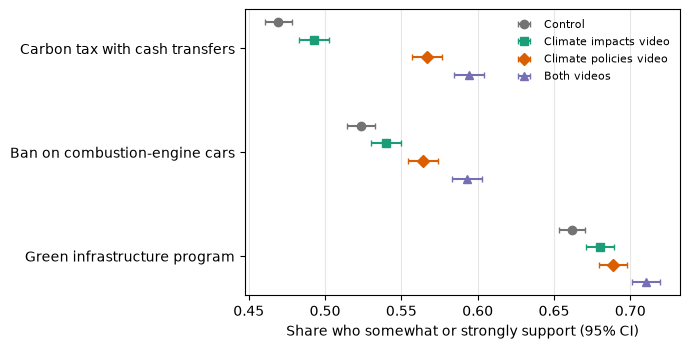

[done]    descriptives in 0s


In [36]:
run("descriptives");

## 3. Generate table to check balance across treatment arms
`Scripts/s03_balance.py`
Outputs: `table_balance.tex`, `fig_balance.pdf`

[running] balance: Balance table and standardized-difference plot
wrote output\tables\table_balance.tex
\begin{tabular}{lrrrr}
\toprule
 & Control & \multicolumn{3}{c}{Difference from control} \\
\cmidrule(lr){3-5}
 & mean & Climate impacts & Climate policies & Both \\
\midrule
Female & 0.504 & $-0.005$ & $-0.001$ & $0.011$ \\
College degree & 0.495 & $-0.000$ & $0.004$ & $0.013^{**}$ \\
Age 50 or older & 0.401 & $-0.005$ & $-0.015^{**}$ & $-0.016^{**}$ \\
Top income quartile & 0.224 & $0.002$ & $-0.000$ & $0.011^{*}$ \\
Has children & 0.439 & $0.002$ & $0.008$ & $0.010$ \\
Interest in politics & 0.138 & $0.015$ & $0.025$ & $0.014$ \\
Left or very left & 0.217 & $-0.002$ & $-0.002$ & $0.002$ \\
Right or very right & 0.316 & $0.004$ & $0.006$ & $0.001$ \\
Urban & 0.730 & $-0.001$ & $0.003$ & $-0.005$ \\
Car dependent & 0.776 & $0.001$ & $-0.004$ & $-0.009$ \\
Public transport availability & 0.280 & $-0.012$ & $0.007$ & $0.033^{**}$ \\
\addlinespace
Joint $F$-test, $p$-value & & 0.972 & 

,F,p,N
Climate impacts,0.355,0.972,21433
Climate policies,0.969,0.472,21427
Both,2.319,0.008,21344


wrote output\figures\fig_balance.pdf


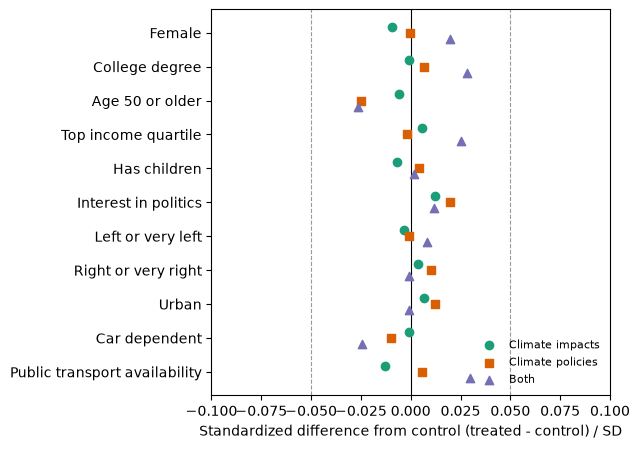

[done]    balance in 3s


In [37]:
run("balance");

## 4. Generate compliance table with the video treatment
`Scripts/s04_compliance.py` · Output: `table_compliance.tex`

In [38]:
run("compliance");

[running] compliance: Compliance table (self-reported video watching)
wrote output\tables\table_compliance.tex
\begin{tabular}{lrrr}
\toprule
 & Climate impacts & Climate policies & Both \\
\midrule
Watched the whole video & 86.0 & 85.1 & 86.2 / 85.6 \\
Did not watch: technical problem & 2.8 & 3.2 & 2.9 / 3.2 \\
Did not watch: skipped part & 2.1 & 2.6 & 2.1 / 2.5 \\
No answer recorded & 9.1 & 9.1 & 8.7 / 8.7 \\
\addlinespace
Respondents & 9,662 & 9,662 & 9,571 \\
\bottomrule
\end{tabular}
[done]    compliance in 0s


## 5. Replication of Table A15 in the original paper
The following runs`Scripts/s05_table_a15.py` to replicate Table A15 of the original paper.
Output: `table_a15.tex`

In [39]:
run("table_a15");

[running] table_a15: Replication of Table A15 (paper's specification)
wrote output\tables\table_a15.tex
\begin{tabular}{lccccc}
\toprule
 & \shortstack{Green\\infrastructure} & \shortstack{Ban on\\combustion cars} & \shortstack{Carbon tax with\\cash transfers} & \shortstack{Fairness\\index} & \shortstack{Willingness to\\change behavior} \\
 & (1) & (2) & (3) & (4) & (5) \\
\midrule
Climate impacts video & $0.019^{***}$ & $0.020^{**}$ & $0.029^{***}$ & $0.045^{***}$ & $0.052^{***}$ \\
 & (0.007) & (0.008) & (0.008) & (0.015) & (0.016) \\
Climate policies video & $0.026^{***}$ & $0.044^{***}$ & $0.102^{***}$ & $0.135^{***}$ & $0.017$ \\
 & (0.007) & (0.008) & (0.008) & (0.015) & (0.016) \\
Both videos & $0.047^{***}$ & $0.073^{***}$ & $0.130^{***}$ & $0.189^{***}$ & $0.075^{***}$ \\
 & (0.007) & (0.008) & (0.008) & (0.015) & (0.016) \\
\addlinespace
Control group mean & 0.658 & 0.516 & 0.459 & -0.083 & -0.031 \\
Observations & 40,680 & 40,680 & 40,680 & 40,680 & 40,680 \\
$R^2$ & 0.096 &

,Impacts,Policies,Both
investments_bin,0.019,0.026,0.047
standard_bin,0.020,0.044,0.073
tax_transfers_bin,0.029,0.102,0.130
index_fairness,0.045,0.135,0.189
index_willing_change,0.052,0.017,0.075


[done]    table_a15 in 2s


---
# B. Linear models and variable selection (Report 3)

## 6. OLS with all pre-treatment controls
`Scripts/s06_ols.py`. Linear probability model, 53 regressors, HC1, unweighted. Output: `table_ols.tex`

In [40]:
run("ols");

[running] ols: OLS with all pre-treatment controls
X: 40,650 x 53 (3 treatment dummies, 31 controls, 19 country dummies); mean of y = 0.527
N = 40,650   R2 = 0.1393


,Coef.,Std.Err.,z,P>|z|,[0.025,0.975]
const,0.1871,0.0174,10.7454,0.0000,0.1530,0.2212
Impacts,0.0268,0.0064,4.1998,0.0000,0.0143,0.0393
Policies,0.0991,0.0064,15.5619,0.0000,0.0866,0.1115
Both,0.1239,0.0064,19.4564,0.0000,0.1114,0.1363
female,-0.0035,0.0049,-0.7190,0.4721,-0.0130,0.0060
college,0.0302,0.0052,5.8015,0.0000,0.0200,0.0404
urban,-0.0043,0.0057,-0.7511,0.4526,-0.0156,0.0069
couple,0.0119,0.0060,1.9966,0.0459,0.0002,0.0237
hh_size,0.0135,0.0025,5.4810,0.0000,0.0086,0.0183
children,0.0333,0.0062,5.4127,0.0000,0.0212,0.0454


wrote output\tables\table_ols.tex
[done]    ols in 0s


## 7. Ridge
`Scripts/s07_ridge.py` · Outputs: `fig_ridge_path.pdf`, `fig_ridge_cv.pdf`

[running] ridge: Ridge: coefficient paths and 5-fold CV
CV-chosen lambda = 0.00123
min CV MSE       = 0.21522   null-model MSE = 0.24925
CV MSE at smallest lambda (~OLS) minus minimum = 7.01e-07
wrote output\figures\fig_ridge_path.pdf


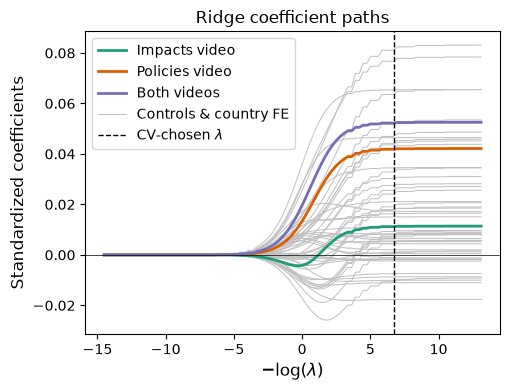

wrote output\figures\fig_ridge_cv.pdf


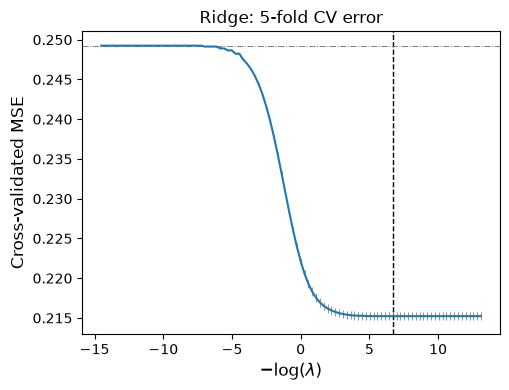

[done]    ridge in 1s


In [41]:
run("ridge");

## 8. Lasso
`Scripts/s08_lasso.py`. CV and 1-SE λ, paths, order of entry. Outputs: `fig_lasso_path.pdf`, `fig_lasso_cv.pdf`

[running] lasso: Lasso: CV and 1-SE lambda, paths, order of entry
CV-chosen lambda = 0.000106   non-zero: 52 of 53
1-SE lambda      = 0.00228   non-zero: 47 of 53
min CV MSE       = 0.21522
dropped at CV min: ['country: PL']
dropped at 1-SE:   ['urban', 'age: 25-34', 'income: Q2', 'employment: Retired', 'econ: Right', 'econ: Very right']
check: max |path - direct fit| = 1.2e-05
wrote output\figures\fig_lasso_path.pdf


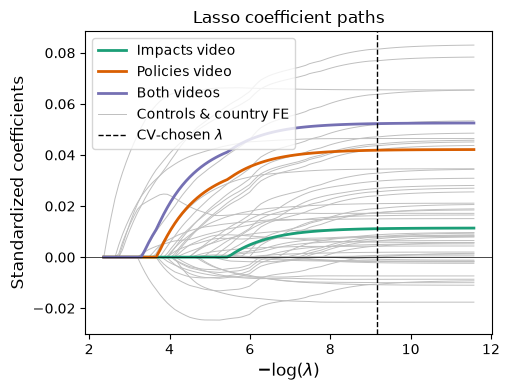

wrote output\figures\fig_lasso_cv.pdf


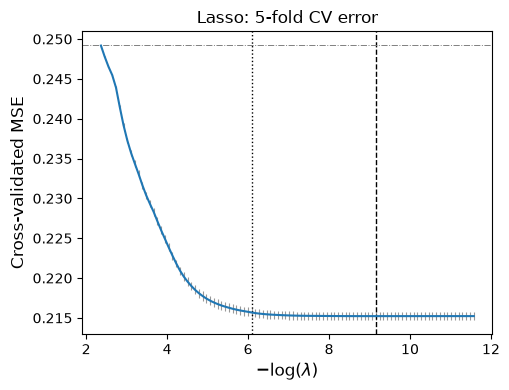

First variables to enter the lasso path:


interested_politics      -2.382766
availability_transport   -2.659215
hh_size                  -2.732934
country: CN              -2.751364
country: IA              -2.788224
country: DE              -3.212112
children                 -3.230541
country: ID              -3.304261
Both                     -3.322691
college                  -3.506990
econ: Left               -3.635999
country: PL              -3.672859
Name: log(lambda) at entry, dtype: float64

[done]    lasso in 2s


In [42]:
run("lasso");

## 9. OLS vs. ridge vs. lasso
`Scripts/s09_compare_linear.py`.
Uses: `ols`, `ridge`, `lasso` · Outputs: `table_ridge_lasso_coefficients.tex`, `table_ridge_lasso_coefficients_clean.tex`

In [43]:
run("compare_linear");

[running] compare_linear: Compare OLS, ridge and lasso; nested-CV test MSE


,OLS,Ridge (CV),Lasso (CV),Lasso (1-SE)
Impacts,0.0268,0.0266,0.0261,0.0126
Policies,0.0991,0.0988,0.0984,0.0846
Both,0.1239,0.1236,0.1232,0.1099
female,-0.0035,-0.0035,-0.0034,-0.0009
college,0.0302,0.0301,0.0300,0.0281
urban,-0.0043,-0.0043,-0.0038,0.0000
couple,0.0119,0.0121,0.0123,0.0172
hh_size,0.0135,0.0136,0.0135,0.0131
children,0.0333,0.0330,0.0327,0.0262
polluting_sector,0.0115,0.0116,0.0113,0.0093


wrote table_ridge_lasso_coefficients.tex and _clean.tex


Null (training mean)    0.24915
OLS                     0.21558
Ridge                   0.21557
Lasso                   0.21557
Name: test MSE, dtype: float64

[done]    compare_linear in 1s


## 10. Double-selection lasso
`Scripts/s10_double_lasso.py`. Post-double selection and partialling out, plug-in and CV λ.
Uses: `ols`, `lasso` · Output: `table_double_lasso.tex`

In [44]:
run("double_lasso");

[skipped] double_lasso  (RUN['double_lasso'] is False)


## 10b. Alternative specification based on the paper's A15 specification for OLS, ridge, and lasso
`Scripts/s11_a15_penalized.py`.

In [45]:
run("a15_penalized");

[skipped] a15_penalized  (RUN['a15_penalized'] is False)


---
# C. Trees and ensembles (Report 4)

## 12. Regression tree
`Scripts/s12_regression_tree.py`. Depth-3 tree, cost-complexity pruning by CV, test MSE.
Outputs: `fig_tree_depth3.pdf`, `fig_tree_cv.pdf`, `fig_tree_pruned.pdf`, `fig_tree_pruned_readable.pdf` (saved only; too large to show here)

In [46]:
run("regression_tree");

[skipped] regression_tree  (RUN['regression_tree'] is False)


## 13. Bagging and random forest
`Scripts/s13_bagging_rf.py`. `max_features` chosen by out-of-bag error; permutation and impurity importance.
Outputs: `fig_rf_importance.pdf`, `table_rf_importance.tex`, `rf_importance_full.csv`

In [47]:
run("bagging_rf");

[skipped] bagging_rf  (RUN['bagging_rf'] is False)


## 14. Boosting
`Scripts/s14_boosting.py`. Learning rates 0.001 and 0.2 (5,000 trees), and 0.01 with early stopping. Output: `fig_boost_error.pdf`

In [48]:
run("boosting");

[skipped] boosting  (RUN['boosting'] is False)


## 15. Error comparison
`Scripts/s15_error_comparison.py`. Test MSE, RMSE and R² on the same test set.
Uses: `compare_linear`, `regression_tree`, `bagging_rf`, `boosting` · Output: `table_error_comparison.tex`

In [49]:
run("error_comparison");

[skipped] error_comparison  (RUN['error_comparison'] is False)


---
# D. Causal graphs (Report 5)

## 16. DAGs
`Scripts/s16_dags.py`. DAG 1 (experiment), DAG 2 (biased sample), DAG 3 (mediator), checked with NetworkX.
Outputs: `fig_dag1_experiment.pdf`, `fig_dag2_biased.pdf`, `fig_dag3_mediator.pdf`, `fig_sutva.pdf`

[running] dags: DAGs 1-3; NetworkX checks


wrote fig_dag1_experiment.pdf
wrote fig_dag2_biased.pdf
wrote fig_dag3_mediator.pdf


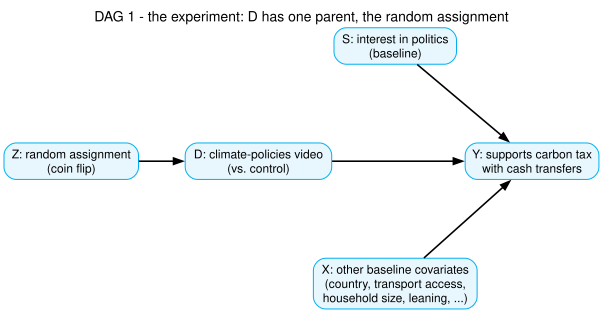

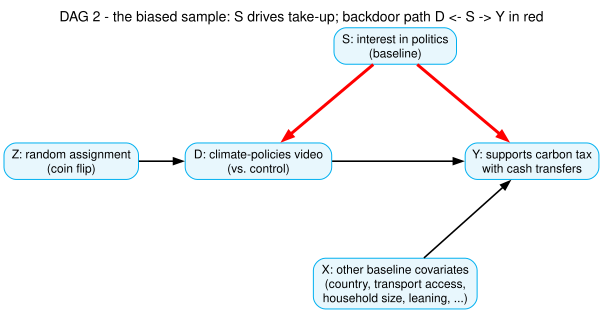

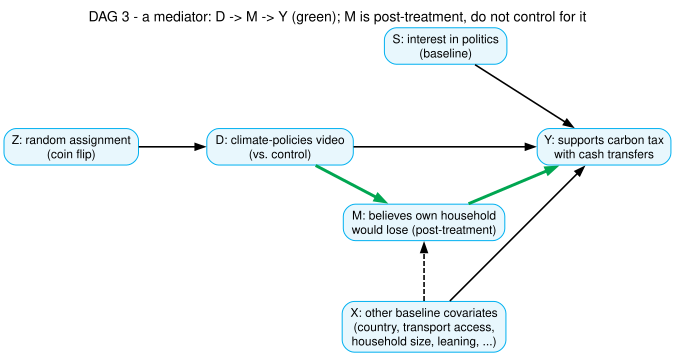

===== DAG 1 - experiment
  acyclic: True   parents of D: ['Z']
  path: D -> Y                   [causal (directed D -> ... -> Y)]
  control for {}: backdoor paths all blocked
===== DAG 2 - biased sample
  acyclic: True   parents of D: ['S', 'Z']
  path: D -> Y                   [causal (directed D -> ... -> Y)]
  path: D <- S -> Y              [backdoor, open]
  control for {}: backdoor paths OPEN
  control for {'S'}: backdoor paths all blocked
  control for {'X'}: backdoor paths OPEN
===== DAG 3 - mediator
  acyclic: True   parents of D: ['Z']
  path: D -> Y                   [causal (directed D -> ... -> Y)]
  path: D -> M -> Y              [causal (directed D -> ... -> Y)]
  path: D -> M <- X -> Y         [non-causal, blocked by collider ['M']]
  control for {}: backdoor paths all blocked
DAG 3 without D -> Y: D and Y d-separated given {}? False
DAG 3 without D -> Y: D and Y d-separated given {'M'}? False
DAG 3 without D -> Y: D and Y d-separated given {'M', 'X'}? True

Adjacency ma

,Z,S,X,D,Y
Z,0,0,0,1,0
S,0,0,0,1,1
X,0,0,0,0,1
D,0,0,0,0,1
Y,0,0,0,0,0


[done]    dags in 3s


In [50]:
run("dags");

---
## Run times

In [52]:
pd.Series(run.timings, name="seconds").round(0)

summary_stats     2.0
descriptives      0.0
balance           3.0
compliance        0.0
table_a15         2.0
ols               0.0
ridge             1.0
lasso             2.0
compare_linear    1.0
dags              3.0
Name: seconds, dtype: float64